<a href="https://colab.research.google.com/github/nccxy/Financial-Odyssey/blob/main/dsa2101_fide_chess_ratings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **DSA2101 Project: FIDE Chess Ratings**
Group Name: Team Elo

Group Members: Ang Sui Yee, Ang Wen Xuan, Cheryl, Guo Tengze, Koh Xuanqi Natalie, Lim Sharn-Cee, Nicole Tan Xin Yi

---



### **Introduction**

The Fédération Internationale des Échecs (FIDE) rating system is a globally recognized method of measuring the skill level of chess players. It is based on the Elo rating system, which updates a player’s rating after each rated game, by comparing the actual result with the expected outcome given the rating difference between opponents. These game-level differences are then summed over the rating period, scaled by a constant known as the K-factor, and rounded to produce the rating change for that period. The K-factor determines how sensitive a player’s rating is to new results – where stronger players tend to have lower K-factors, leading to smaller fluctuations. As a result, ratings are dynamic and can fluctuate over time, especially in the short term.

Understanding what drives short term changes in rating changes is crucial for evaluating a player’s performance, identifying patterns of improvements or decline and providing insights for both players and coaches to prepare more effectively for competitions. This project is guided by the question: **What are the major factors that drive short-term changes in ratings?** Using player statistics from the August and September 2025 TidyTuesday datasets, we investigate the key influences behind rating fluctuations. In particular, <u>we examine three main factors: age, federation and gender</u>. First, for age, we investigate whether age affects rating volatility. Second, for federation, we investigate whether players from more active federations experience more volatile ratings. Third, for gender, we ask what may underlie the rating gap between men and women players. To ensure a consistent basis for comparison, we assume that ratings are recorded at the start of each month. Thus, the observed rating change between August and September reflects only the games played in August.

The two files record one player per row and include FIDE id, name, federation, sex, title information, standard rating, number of games played in the month, K-factor, and birth year variables, so the data provides basic information about the player and the strength of the player as shown in the table below.
| Column | Description |
|--------|------------|
| id | The player’s ID, a unique number for each player |
| name | The player’s name in the data |
| fed | National chess federation code (similar to IOC country codes) |
| sex | The player’s recorded sex |
| title | The player's chess title (GM, IM, FM, CM, WGM, etc.) if any |
| wtitle | A women’s title held by the player (WGM, WIM, WFM, WCM) |
| otitle | Other official chess-related titles held by the player(IA, FA, NA, IO, FT, FST, DI, NI) |
| foa | FIDE Online Arena title (AGM, AIM, AFM, ACM) |
| rating | The player’s standard FIDE chess rating, based on the Elo system. A higher value generally means a stronger player |
| games | Number of rated games played that month |
| k | K-factor controlling rating volatility |
| bday | Player's year of birth |

### **Data Cleaning and Summary**

The dataset was first cleaned by standardising missing values and checking for inconsistencies across the August and September files. Since player IDs were not unique identifiers on their own, the data was merged using both ID and name to ensure accurate matching of individuals across months. Duplicate entries within each dataset were verified to be consistent, as no duplicates existed for the same ID–name pair. Additional checks were performed to identify mismatches in key variables. A small number of observations with inconsistent birth years across months were removed to maintain data integrity. Finally, a new variable measuring rating change (rating_sep - rating_aug) was constructed, forming the basis for subsequent analysis across all three plots.

In [ ]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
import plotly.io as pio
pio.renderers.default = "notebook_connected"

In [ ]:
ratings_aug = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-23/fide_ratings_august.csv',  na_values=['NA', 'na', 'N/A', 'Na', ''])
ratings_sep = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-23/fide_ratings_september.csv', na_values=['NA', 'na', 'N/A', 'Na', ''])

*checking for missing / NA values*

In [ ]:
ratings_aug.isna().sum()

,0
id,0
name,0
fed,0
sex,0
title,188366
wtitle,198756
otitle,198997
foa,196707
rating,0
games,0


In [ ]:
ratings_sep.isna().sum()

,0
id,0
name,0
fed,0
sex,0
title,190523
wtitle,200946
otitle,201168
foa,198860
rating,0
games,0


*merging - finding unique identifier*

In [ ]:
# To show that id by itself is not a unique identifier
test1 = ratings_aug.merge(ratings_sep, on='id', how='inner', suffixes=['_aug', '_sep'])

# Find rows where names are different
name_mismatches = test1[test1['name_aug'] != test1['name_sep']][['id', 'name_aug', 'name_sep']]
print(len(name_mismatches))
name_mismatches.head()

# There are duplicate ids across files

85


,id,name_aug,name_sep
773,44703929,"Abdrasul, Dias","Borges, Lucas Farah Machado"
1117,54707528,Abhijeet Bharti,"Lafuente Garcia, Ian"
1763,54705959,"Acosta Choursan, Hector",Harsh Prabhat
3004,20018371,"Aguilar, Daniel","Aguilar, Daniel Ernesto"
5409,44701845,"Aliakbar, Alizhan","De Moura Silva, Guilherme"


In [ ]:
# Are there duplicates of id/names in each file - yes

print(ratings_aug['id'].duplicated().sum())
print(ratings_sep['id'].duplicated().sum())

print(ratings_aug['name'].duplicated().sum())
print(ratings_sep['name'].duplicated().sum())

32
35
1402
1447


In [ ]:
print(ratings_aug.duplicated(subset=['id', 'name']).sum())
print(ratings_sep.duplicated(subset=['id', 'name']).sum())

# id + name can uniquely identify players


0
0


*actual merging*

In [ ]:
# Merge on both id & name
ratings_merged = ratings_aug.merge(ratings_sep, on = ['id', 'name'], how = 'inner', suffixes = ['_aug', '_sep'])
ratings_merged.head()

,id,name,fed_aug,sex_aug,title_aug,wtitle_aug,otitle_aug,foa_aug,rating_aug,games_aug,...,fed_sep,sex_sep,title_sep,wtitle_sep,otitle_sep,foa_sep,rating_sep,games_sep,k_sep,bday_sep
0,53707043,A Darshil,IND,M,NaN,NaN,NaN,NaN,1412,4,...,IND,M,NaN,NaN,NaN,NaN,1412,0,40,2013
1,53200465,"A F M Ehteshamul, Hoque (tuhin",BAN,M,NaN,NaN,NaN,NaN,1797,0,...,BAN,M,NaN,NaN,NaN,NaN,1797,0,40,1977
2,5716365,"A Hamid, Harman",MAS,M,NaN,NaN,NaN,NaN,1552,0,...,MAS,M,NaN,NaN,NaN,NaN,1552,0,20,1970
3,53200553,A I Sabbir,BAN,M,NaN,NaN,NaN,NaN,1607,0,...,BAN,M,NaN,NaN,NaN,NaN,1607,0,40,1995
4,5045886,"A K, Kalshyan",IND,M,NaN,NaN,NaN,NaN,1747,0,...,IND,M,NaN,NaN,NaN,NaN,1747,0,20,1964


In [ ]:
ratings_merged.shape

(195960, 22)

In [ ]:
# Add ratings change column
ratings_merged['rating_change'] = ratings_merged['rating_sep'] - ratings_merged['rating_aug']
ratings_merged.head()

,id,name,fed_aug,sex_aug,title_aug,wtitle_aug,otitle_aug,foa_aug,rating_aug,games_aug,...,sex_sep,title_sep,wtitle_sep,otitle_sep,foa_sep,rating_sep,games_sep,k_sep,bday_sep,rating_change
0,53707043,A Darshil,IND,M,NaN,NaN,NaN,NaN,1412,4,...,M,NaN,NaN,NaN,NaN,1412,0,40,2013,0
1,53200465,"A F M Ehteshamul, Hoque (tuhin",BAN,M,NaN,NaN,NaN,NaN,1797,0,...,M,NaN,NaN,NaN,NaN,1797,0,40,1977,0
2,5716365,"A Hamid, Harman",MAS,M,NaN,NaN,NaN,NaN,1552,0,...,M,NaN,NaN,NaN,NaN,1552,0,20,1970,0
3,53200553,A I Sabbir,BAN,M,NaN,NaN,NaN,NaN,1607,0,...,M,NaN,NaN,NaN,NaN,1607,0,40,1995,0
4,5045886,"A K, Kalshyan",IND,M,NaN,NaN,NaN,NaN,1747,0,...,M,NaN,NaN,NaN,NaN,1747,0,20,1964,0


In [ ]:
# Check if there's bday mismatch
bday_mismatches = ratings_merged[ratings_merged['bday_aug'] != ratings_merged['bday_sep']]
bday_mismatches


,id,name,fed_aug,sex_aug,title_aug,wtitle_aug,otitle_aug,foa_aug,rating_aug,games_aug,...,sex_sep,title_sep,wtitle_sep,otitle_sep,foa_sep,rating_sep,games_sep,k_sep,bday_sep,rating_change
45239,13762648,"Dosmagambetov, Rakhat",KAZ,M,NaN,NaN,NaN,NaN,1400,0,...,M,NaN,NaN,NaN,NaN,1400,0,40,2006,0
118357,11020180,Muchesera Roland,ZIM,M,NaN,NaN,NaN,NaN,1823,0,...,M,NaN,NaN,NaN,NaN,1867,8,40,2004,44
167619,10039414,Ssekyewa Rayan Diini,UGA,M,NaN,NaN,NaN,NaN,1605,0,...,M,NaN,NaN,NaN,NaN,1605,0,40,2001,0


In [ ]:
# 3 mismatch, drop these people
ratings_merged = ratings_merged[ratings_merged['bday_aug'] == ratings_merged['bday_sep']]
ratings_merged.shape

(195957, 23)

## **Age**
***Sub Question:  Does age affect rating volatility?***

**Data Cleaning and Summary for Age**

A glance at the dataframe revealed that a large number of players had a rating change of 0. We found that 159,044 out of 195,957 players (~81%) experienced no rating change, which might be due to inactivity, or wins and losses cancelling out exactly. Since players with no rating change offer no meaningful signal for studying rating volatility, they were excluded regardless of whether they had played games, leaving 36,913 players for analysis.

An age column was then added before players were split into age groups. The age groups were adapted from the official FIDE tournament categories, with the open category (21+) further segmented for more granular insight.

Observing differences in rating changes across age groups, we investigated whether game volume might be a contributing factor. Looking at the mean number of games played in August, players aged U12 to 29 played the most games, averaging 4 - 5 games, with U16 players peaking at 5 games on average. The relationship between games played and rating change is then explored further with the plot.


In [ ]:
# How many players have rating change = 0
print(ratings_merged[ratings_merged['rating_change']== 0].shape)

# How many players in total
print(ratings_merged.shape)

# 159044 out of 195957 players have no rating change (a large proportion)
    # Might be due to: 1. Inactivity 2. Wins and losses cancel out exactly

# Players whose ratings never changed contribute no information to studying rating change volatility, even if they played games

(159044, 23)
(195957, 23)


In [ ]:
# Remove players with no rating change to make study more meaningful
ratings_merged = ratings_merged[ratings_merged['rating_change'] != 0]
ratings_merged

# Explore 36913 players

,id,name,fed_aug,sex_aug,title_aug,wtitle_aug,otitle_aug,foa_aug,rating_aug,games_aug,...,sex_sep,title_sep,wtitle_sep,otitle_sep,foa_sep,rating_sep,games_sep,k_sep,bday_sep,rating_change
6,10257853,"A, L M Wayes Faruki",BAN,M,NaN,NaN,NaN,NaN,1765,0,...,M,NaN,NaN,NaN,NaN,1802,5,40,2015,37
15,10276971,"Aabid, Mahadi Saad",BAN,M,NaN,NaN,NaN,NaN,1675,0,...,M,NaN,NaN,NaN,NaN,1681,6,40,2010,6
20,53702654,Aadam Johan Bibin,IND,M,NaN,NaN,NaN,NaN,1612,0,...,M,NaN,NaN,NaN,NaN,1430,15,40,2017,-182
22,42905337,Aadarsh Kumar Beriha,IND,M,NaN,NaN,NaN,NaN,1640,0,...,M,NaN,NaN,NaN,NaN,1629,19,40,2013,-11
26,88105571,Aadarsh Saraswat,IND,M,NaN,NaN,NaN,NaN,1709,9,...,M,NaN,NaN,NaN,NaN,1692,8,40,2010,-17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195915,1036432,"Zwirs, Nico",NED,M,IM,NaN,NaN,NaN,2436,16,...,M,IM,NaN,NaN,NaN,2432,9,10,1994,-4
195921,40111318,"Zyat, Jamal",NED,M,NaN,NaN,NaN,NaN,1754,0,...,M,NaN,NaN,NaN,NaN,1732,4,40,1988,-22
195928,91170958,"Zygadlo, Aleksander",POL,M,NaN,NaN,NaN,NaN,1517,0,...,M,NaN,NaN,NaN,NaN,1467,7,40,2016,-50
195931,1125729,"Zygmunt, Piotr",POL,M,NaN,NaN,NaN,NaN,1647,0,...,M,NaN,NaN,NaN,NaN,1645,5,20,1970,-2


In [ ]:
# Data Cleaning
# Add age column & remove bday column
ratings_merged = ratings_merged.drop(columns=['bday_sep'])
ratings_merged = ratings_merged.rename(columns={'bday_aug': 'bday'})

ratings_merged['age'] = 2025 - ratings_merged['bday'] # dataset from 2025
ratings_merged = ratings_merged.drop(columns = ['bday'])

In [ ]:
# Subset to include relevant columns only
df = ratings_merged[['id','name','rating_change','age','games_aug']].copy()

In [ ]:
# Split players into different age groups (modified from the FIDE age groups):
  # U8-U20 age groups: grouped based on FIDE official tournament categories
  # Adult players (21 and above): grouped in broader intervals as their ratings tend to be more stable

df['fide_age_group'] = pd.cut(df['age'],
                               bins=[0, 8, 10, 12, 14, 16, 18, 20, 29, 39, 49, 64, 100],
                               labels=['U8', 'U10', 'U12', 'U14', 'U16',
                                       'U18', 'U20', '21-29','30-39', '40-49', '50-64', '65+'])

df.head()

,id,name,rating_change,age,games_aug,fide_age_group
6,10257853,"A, L M Wayes Faruki",37,10,0,U10
15,10276971,"Aabid, Mahadi Saad",6,15,0,U16
20,53702654,Aadam Johan Bibin,-182,8,0,U8
22,42905337,Aadarsh Kumar Beriha,-11,12,0,U12
26,88105571,Aadarsh Saraswat,-17,15,9,U16


In [ ]:
# Why do some age groups have different rating volatility? Could it be related to the number of games they played?

# Explore mean number of games played per age group in Aug
round(df.groupby('fide_age_group', observed=True)[['games_aug']].mean(), 1)

,games_aug
fide_age_group,
U8,3.8
U10,3.8
U12,4.0
U14,4.3
U16,5.0
U18,4.9
U20,4.6
21-29,4.0
30-39,2.9


In [ ]:
# Visualisation
groups = df['fide_age_group'].cat.categories.tolist()

fig = make_subplots(
    rows=2, cols=1,
    subplot_titles=('Rating change volatility by age group',
                    'Mean games played (Aug) by age group'),
    vertical_spacing=0.2,
    row_heights=[0.6, 0.3])

# Box plot (Top)
for group in groups:
    subset = df[df['fide_age_group'] == group]['rating_change'].dropna()
    group_data = df[df['fide_age_group'] == group]

    q1 = subset.quantile(0.25)
    q3 = subset.quantile(0.75)
    iqr = q3 - q1
    whisker_low = subset[subset >= q1 - 1.5*iqr].min()
    whisker_high = subset[subset <= q3 + 1.5*iqr].max()
    median = subset.median()

    # Calculations for mean games & number of players in each age group (to be showed when hovering)
    mean_games = round((group_data['games_aug']).mean(), 1)
    n_players = len(group_data)
    color = 'red' if median < 1 else 'green'

    fig.add_trace(go.Box(
        q1=[q1], median=[median], q3=[q3],
        lowerfence=[whisker_low],
        upperfence=[whisker_high],
        name=str(group),
        x=[str(group)],
        marker_color=color,
        line_color=color,
        boxpoints=False,
        hoverinfo='skip',
        showlegend=False
    ), row=1, col=1)

    fig.add_trace(go.Scatter(
        x=[str(group)],
        y=[median],
        mode='markers',
        marker=dict(size=14, color='rgba(0,0,0,0)'),
        showlegend=False,
        hovertemplate=(
            f"<b>{group}</b><br>"
            f"Median: {round(median, 1)}<br>"
            f"IQR: {round(iqr, 1)}<br>"
            f"Avg games played (Aug): {mean_games}<br>"
            f"Players: {n_players}"
            "<extra></extra>"
        )
    ), row=1, col=1)

# Bar chart (Bottom)
mean_games_by_group = (
    df.dropna(subset=['fide_age_group'])
    .groupby('fide_age_group', observed=True)['games_aug']
    .mean()
    .reset_index()
)

mean_games_by_group.columns = ['fide_age_group', 'mean_games']

fig.add_trace(go.Bar(
    x=mean_games_by_group['fide_age_group'].astype(str),
    y=mean_games_by_group['mean_games'],
    marker_color='steelblue',
    showlegend=False,
    hovertemplate='<b>%{x}</b><br>Mean games: %{y:.1f}<extra></extra>'
), row=2, col=1)

# Legend for box plot
fig.add_trace(go.Scatter(
    x=[None], y=[None],
    mode='markers',
    marker=dict(size=10, color='green', symbol='square'),
    name='Median > 0 (gaining)',
    showlegend=True
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=[None], y=[None],
    mode='markers',
    marker=dict(size=10, color='red', symbol='square'),
    name='Median < 0 (losing)',
    showlegend=True
), row=1, col=1)

# Layout
fig.update_layout(
    title=dict(
        text='<b>Rating Change Volatility by Age Group</b>',
        x=0.5,
        xanchor='center',
        font=dict(size=23)
    ),
    showlegend=True,
    legend=dict(orientation='h', yanchor='bottom', y=0.95,
                xanchor='right', x=1),
    plot_bgcolor='white',
    paper_bgcolor='white',
    font=dict(size=12),
    hoverlabel=dict(bgcolor='white', font_size=12),
    height=800,
    width=1000
)

fig.update_xaxes(showgrid=False)
fig.update_yaxes(
    title_text='Rating change',
    title_standoff=10,
    gridcolor='rgba(0,0,0,0.08)',
    zeroline=True, zerolinecolor='gray', zerolinewidth=1,
    row=1, col=1
)
fig.update_yaxes(
    title_text='Mean games played',
    title_standoff=25,
    showgrid=True,
    gridwidth=0.5,
    gridcolor='gray',
    row=2, col=1
)
fig.update_xaxes(title_text='Age Group', row=2, col=1)
fig.update_traces(hoverinfo='skip', selector=dict(type='box'))

fig.show()

## **Federation**
***Sub Question: Is rating volatility higher among more active federations?***

**Data Cleaning and Summary for Federation**

To ensure consistency in federation-level analysis, we restricted the dataset to players who did not change federations between August and September. This avoids attributing rating changes to the wrong country. We then excluded very small federations (fewer than 30 players) to reduce noise from small sample sizes, where volatility estimates can be unstable. At the aggregation stage, we computed three key variables at the federation level: (i) number of players, (ii) activity rate (percentage of players with at least one game in August), and (iii) rating volatility, measured as the standard deviation of non-zero rating changes.

Across the filtered sample, there are 93 federations with at least one active player in August, indicating broad global participation but uneven competitive intensity. Activity rates vary substantially across countries, with the top federations (e.g. NZL, ESA, MGL) exceeding 80% participation, suggesting highly engaged player bases. In contrast, rating volatility shows a different pattern. The most volatile federations (e.g. KEN, BLR, UAE) exhibit standard deviations above 55, far higher than the global average. Notably, high activity does not necessarily correspond to high volatility. Some highly active federations maintain relatively stable ratings, while others with moderate activity display large fluctuations.


In [ ]:
# Data Cleaning
ratings_merged_fed = ratings_merged[
    ratings_merged['fed_aug'] == ratings_merged['fed_sep'] ##keep only players who didnt change feds
].copy()
# Exclude feds that are too small
counts_fed = ratings_merged_fed['fed_aug'].value_counts()
print(counts_fed)
valid_feds = counts_fed[counts_fed >= 30].index
print(valid_feds)
ratings_merged_fed = ratings_merged_fed[
    ratings_merged_fed['fed_aug'].isin(valid_feds)
]

fed_aug
IND    3462
ESP    2653
GER    2026
FRA    1973
POL    1543
       ... 
SEY       1
VIN       1
PNG       1
MAC       1
DJI       1
Name: count, Length: 163, dtype: int64
Index(['IND', 'ESP', 'GER', 'FRA', 'POL', 'USA', 'RUS', 'IRI', 'ITA', 'CZE',
       'TUR', 'SUI', 'ENG', 'NED', 'ROU', 'KAZ', 'BEL', 'HUN', 'ARG', 'CHN',
       'BRA', 'AUS', 'SRI', 'PER', 'GRE', 'CAN', 'ISR', 'SWE', 'BAN', 'SVK',
       'AUT', 'SRB', 'AZE', 'PHI', 'UKR', 'IRL', 'MEX', 'CRO', 'COL', 'CHI',
       'ARM', 'FID', 'BUL', 'UZB', 'DEN', 'GEO', 'RSA', 'VEN', 'EGY', 'ZAM',
       'NOR', 'KGZ', 'POR', 'CUB', 'MAD', 'SLO', 'LAT', 'LTU', 'NZL', 'BOL',
       'WLS', 'VIE', 'JOR', 'UAE', 'FIN', 'SCO', 'KOR', 'KEN', 'ESA', 'ECU',
       'ZIM', 'MAS', 'LBA', 'MDA', 'ALG', 'NGR', 'MKD', 'MAR', 'OMA', 'URU',
       'HKG', 'BLR', 'PAR', 'EST', 'LBN', 'PAN', 'CRC', 'MGL', 'MNE', 'MLT',
       'PLE', 'KSA', 'PUR'],
      dtype='object', name='fed_aug')


In [ ]:
# Aggregations
df = (
    ratings_merged_fed
    .groupby('fed_aug')
    .agg(
        num_players=('fed_aug', 'size'),
        active_rate=('games_aug', lambda x: (x > 0).mean() * 100),
        volatility=('rating_change', lambda x: x[x != 0].std())
    )
    .reset_index()
    .rename(columns={'fed_aug': 'federation'})
)
df = df.dropna(subset=['volatility'])

# Rankings (for annotation purposes)
df['vol_rank'] = df['volatility'].rank(ascending=False, method='min').astype(int)
df['act_rank'] = df['active_rate'].rank(ascending=False, method='min').astype(int)

top5_vol = df.nsmallest(5, 'vol_rank')
top5_act = df.nsmallest(5, 'act_rank')
max_vol = df.loc[df['volatility'].idxmax()]
max_act = df.loc[df['active_rate'].idxmax()]
num_active_feds = ratings_merged_fed[ratings_merged_fed['games_aug'] > 0]['fed_aug'].nunique()


In [ ]:
# Visualization

# Text boxes for top ranking countries (formating/preparation steps)
vol_text = "<b>Top 5 Volatility</b><br>"
for _, r in top5_vol.iterrows():
    vol_text += f"#{r['vol_rank']} {r['federation']} {r['volatility']:.2f}<br>"

act_text = "<b>Top 5 Activity</b><br>"
for _, r in top5_act.iterrows():
    act_text += f"#{r['act_rank']} {r['federation']} {r['active_rate']:.1f}%<br>"

fig4 = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Activity Rate (Aug)", "Rating Volatility (Sep − Aug)"),
    specs=[[{"type": "choropleth"}, {"type": "choropleth"}]]
)

# Activity rate plot (left)
fig4.add_trace(go.Choropleth(
    locations=df['federation'],
    z=df['active_rate'],
    locationmode='ISO-3',
    colorscale='Oranges',
    colorbar=dict(title='Active Rate (%)', x=0.46),
    customdata=df[['num_players', 'volatility', 'act_rank']],
    hovertemplate=(
        '<b>%{location}</b><br>'
        'Active Rate: %{z}%<br>'
        'Rank: #%{customdata[2]}<br>'
        'Players: %{customdata[0]}<br>'
        'Volatility: %{customdata[1]}<br>'
        '<extra></extra>'
    )
), row=1, col=1)

# Volatility plot (right)
fig4.add_trace(go.Choropleth(
    locations=df['federation'],
    z=df['volatility'],
    locationmode='ISO-3',
    colorscale='Oranges',
    zmin=0, # force scale to start from 0
    zmax=df['volatility'].max(),
    colorbar=dict(title='Volatility (std)', x=1.01),
    customdata=df[['num_players', 'active_rate', 'vol_rank']],
    hovertemplate=(
        '<b>%{location}</b><br>'
        'Volatility: %{z}<br>'
        'Rank: #%{customdata[2]}<br>'
        'Players: %{customdata[0]}<br>'
        'Active Rate: %{customdata[1]}%<br>'
        '<extra></extra>'
    )
), row=1, col=2)

# Annotations (rankings text boxes and title)
existing_annotations = fig4.layout.annotations
fig4.update_layout(
    annotations=list(existing_annotations) + [
        dict( ##text box for top 5 activity rate
            x=0.01, y=0.05,
            xref='paper', yref='paper',
            text=act_text,
            showarrow=False,
            align='left',
            font=dict(size=10),
            bordercolor='black',
            borderwidth=1,
            bgcolor='white'
        ),
        dict( ##text box for top 5 volatility
            x=0.6, y=0.05,
            xref='paper', yref='paper',
            text=vol_text,
            showarrow=False,
            align='left',
            font=dict(size=10),
            bordercolor='black',
            borderwidth=1,
            bgcolor='white'
        ),
        dict(
            x=0.5, y=1.06,
            xref='paper', yref='paper',
            text=f"There are {num_active_feds} countries with non-zero games in Aug.",
            showarrow=False,
            font=dict(size=11, color='gray'),
            align='center'
        )
    ],
    title='Federation Activity vs Volatility', title_x=0.45,
    width=1400, height=500,
    margin=dict(l=0, r=80, t=60, b=0)
)

fig4.update_geos(
    showframe=True,
    framecolor='black',
    showcoastlines=True,
    projection_type='natural earth',
    fitbounds="locations"
)

fig4.show()

## **Gender**
***Sub question: Is Gender a determining and fair factor in driving volatility of ratings?***

**Data cleaning and Summary for Gender**

During data cleaning, we found that only two players had different recorded sexes between the August and September files and their rating change were small (only 2), hence little data cleaning was performed. As the games played were based in the month of August, the gender recorded in the 'sex_aug' column was used. An intuition that comes to mind when investigating the significance gender in determining rating volatility is to understand if the rating system fairly represents women. As women only make up 10.3 percent of active chess players in this data set, this makes it even rarer to see women with high ratings. This is seen by the fact that as of August, only 33 women (0.16% of women players) hold the Grandmaster (GM) title compared to 1273 men (0.71% of men players). However, studies have shown that when men and women are given the same conditions from young, they are equally likely to be good at chess (Doggers, 2025). Hence, we would conduct further examinations to understand the nuance in how different men and women's rating volatility is.

In [ ]:
# subset women
womens_title_august = ratings_aug[ratings_aug['sex'] == 'F']
# filter women with titles
womens_title_august = womens_title_august[(~womens_title_august['wtitle'].isna()) |
                                          (~womens_title_august['title'].isna())].reset_index()
womens_title_august.head()


,index,id,name,fed,sex,title,wtitle,otitle,foa,rating,games,k,bday
0,105,48701955,Aadya Gowda,IND,F,WCM,WCM,NaN,NaN,1808,9,40,2013
1,106,25778293,Aadya Gupta,IND,F,WFM,WFM,NaN,NaN,1923,0,40,2010
2,108,25991426,Aadya Ranganath,IND,F,WCM,WCM,NaN,NaN,1874,0,40,2013
3,127,25014510,Aakanksha Hagawane,IND,F,WIM,WIM,NaN,NaN,2320,0,20,2000
4,148,33486697,Aamuktha Guntaka,IND,F,WCM,WCM,NaN,NaN,2062,5,40,2012


In [ ]:
women_open_titles = womens_title_august.copy()
womens_titles = ['WGM', 'WIM', 'WFM', 'WCM']

# titles also contained womens titles if the individual did not hold an open title
# title: set to NaN if it's a women's title (keep only open titles here)
women_open_titles['title'] = women_open_titles['title'].where(
    ~women_open_titles['title'].isin(womens_titles), other=np.nan)

women_open_titles.head()

,index,id,name,fed,sex,title,wtitle,otitle,foa,rating,games,k,bday
0,105,48701955,Aadya Gowda,IND,F,NaN,WCM,NaN,NaN,1808,9,40,2013
1,106,25778293,Aadya Gupta,IND,F,NaN,WFM,NaN,NaN,1923,0,40,2010
2,108,25991426,Aadya Ranganath,IND,F,NaN,WCM,NaN,NaN,1874,0,40,2013
3,127,25014510,Aakanksha Hagawane,IND,F,NaN,WIM,NaN,NaN,2320,0,20,2000
4,148,33486697,Aamuktha Guntaka,IND,F,NaN,WCM,NaN,NaN,2062,5,40,2012


In [ ]:
# subset men with titles
men_title_august = ratings_aug[ratings_aug['sex'] == 'M']
men_title_august = men_title_august[(~men_title_august['title'].isna())].reset_index()
men_title_august.head()

,index,id,name,fed,sex,title,wtitle,otitle,foa,rating,games,k,bday
0,9,1701991,"Aaberg, Anton",SWE,M,IM,NaN,NaN,NaN,2328,0,10,1972
1,18,1407589,"Aabling-Thomsen, Jakob",DEN,M,IM,NaN,NaN,NaN,2337,0,10,1985
2,80,25678191,Aaditya Dhingra,IND,M,IM,NaN,NaN,NaN,2394,12,10,2006
3,112,1401815,"Aagaard, Jacob",DEN,M,GM,NaN,NaN,NaN,2436,0,10,1973
4,130,25644394,Aakash G,IND,M,FM,NaN,NaN,NaN,2271,17,20,2010


In [ ]:
# Count GM men from men_title_august
GM_men_count = len(men_title_august[men_title_august['title'] == 'GM'])

# Count GM women from women_open_titles
GM_women_count = len(women_open_titles[women_open_titles['title'] == 'GM'])

# Get total populations (make sure you have these DataFrames)
# Assuming ratings_aug has the full population
total_men = len(ratings_aug[ratings_aug['sex'] == 'M'])
total_women = len(ratings_aug[ratings_aug['sex'] == 'F'])

# Calculate percentages
GM_men_percent = (GM_men_count / total_men) * 100 if total_men > 0 else 0
GM_women_percent = (GM_women_count / total_women) * 100 if total_women > 0 else 0

# Create output
print(f"GM Men: {GM_men_count} ({GM_men_percent:.2f}% of male population)")
print(f"GM Women: {GM_women_count} ({GM_women_percent:.2f}% of female population)")
print(f"Total GM: {GM_men_count + GM_women_count}")
print(f"Percentage of Total Female players {100 * total_women / (total_women + total_men):.1f}%")

GM Men: 1273 (0.71% of male population)
GM Women: 33 (0.16% of female population)
Total GM: 1306
Percentage of Total Female players 10.3%


/tmp/ipykernel_45697/2263685840.py:61: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



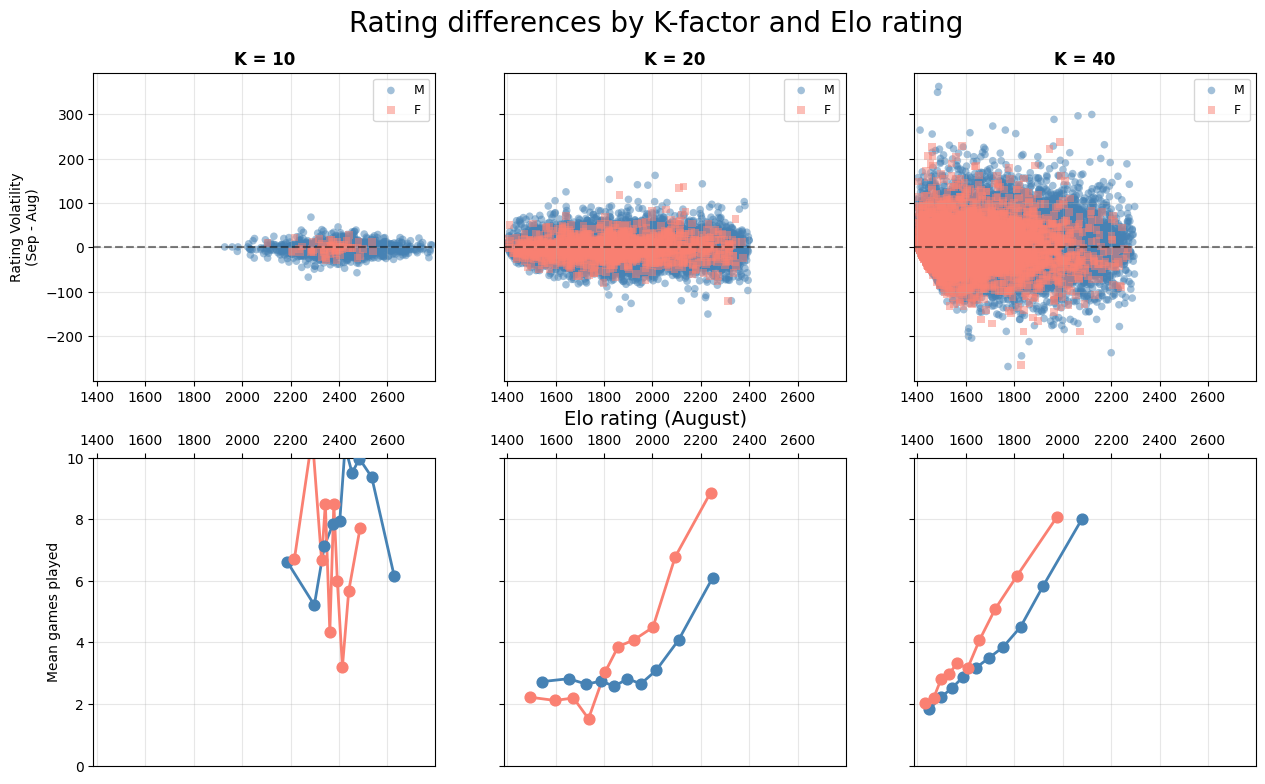

In [ ]:
# Visualisation
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey='row',
                         gridspec_kw={'height_ratios': [1, 1], 'hspace': 0.25})

# Top row: Scatter plots of rating volatility according to different K factors, men and women differentiated
for idx, k in enumerate(sorted(ratings_merged['k_aug'].unique())):

    ax_scatter = axes[0, idx]
    data = ratings_merged[ratings_merged['k_aug'] == k].dropna(subset=['rating_change', 'rating_aug'])

    for sex, color, marker in [('M', 'steelblue', 'o'), ('F', 'salmon', 's')]:
        subset = data[data['sex_aug'] == sex]
        ax_scatter.scatter(subset['rating_aug'], subset['rating_change'],
                           alpha=0.5, s=30, color=color, marker=marker, label=sex, edgecolors='none')

    ax_scatter.axhline(0, color='black', linestyle='--', alpha=0.5)
    ax_scatter.set_title(f'K = {k}', fontsize=12, fontweight='bold')
    if idx == 0:
        ax_scatter.set_ylabel('Rating Volatility\n(Sep - Aug)', fontsize=10)
    ax_scatter.legend(loc='upper right', fontsize=9)
    ax_scatter.grid(alpha=0.3, axis='both')
     # Top row: show x-ticks at bottom, no labels
    ax_scatter.tick_params(axis='x', labelbottom=True, bottom=True, top=False)


    # Bottom row: mean games played according to different K values
    ax_density = axes[1, idx]

    for sex, color in [('M', 'steelblue'), ('F', 'salmon')]:
        subset = data[data['sex_aug'] == sex].dropna(subset=['rating_aug', 'games_aug'])
        subset = subset.copy()
        subset['rating_bin'] = pd.qcut(subset['rating_aug'], q=10, duplicates='drop')
        grouped = subset.groupby('rating_bin', observed=True).agg(
            mid=('rating_aug', 'median'),
            mean_games=('games_aug', 'mean'),
        ).reset_index()

        ax_density.plot(grouped['mid'], grouped['mean_games'], color=color, linewidth=2)
        ax_density.scatter(grouped['mid'], grouped['mean_games'], color=color, s=60, zorder=3)

    if idx == 0:
        ax_density.set_ylabel('Mean games played', fontsize=10)
    ax_density.grid(alpha=0.3, axis='both')

        # Bottom row: show x-ticks at top, no labels
    ax_density.tick_params(axis='x', labelbottom=False, labeltop=True, bottom=False, top=True)

# Clip y-axis of bottom row to a sensible range
axes[1, 0].set_ylim(0, ratings_merged['games_aug'].quantile(0.90))


# X limits
all_ratings = ratings_merged['rating_aug'].dropna()
x_min, x_max = all_ratings.min(), all_ratings.max()
x_padding = (x_max - x_min) * 0.01
for ax in axes.flat:
    ax.set_xlim(x_min - x_padding, x_max + x_padding)

fig.text(0.5, 0.495, 'Elo rating (August)', ha='center', va='center', fontsize=14)
plt.suptitle('Rating differences by K-factor and Elo rating', fontsize=20, y=0.95)
plt.tight_layout()
plt.subplots_adjust(hspace=0.5)
plt.show()

## **Discussion**

The box plot explores the relationship between age and rating volatility. Rating volatility here refers to how and by how much ratings change for each age group from August to September. Some key insights from the plot are as follows: Looking at the <u>median rating change</u>, players aged U12 to 29 exhibit rating gains (medians range from +1 to +7), peaking at U16 (+7). In contrast, younger children (U8: −10, U10: −4) and older players (30+: −2 to −7) tend to experience net rating losses. This pattern reflects the typical developmental trajectory of a chess player. Younger children are still building foundational skills and are more likely to lose against more experienced opponents, resulting in rating declines. As players progress into their teenage years, increased experience and skill development contribute to consistent rating gains, culminating in a peak during early adulthood. Beyond this stage, players aged 30 and above tend to show slight rating declines, which may be attributed to reduced training intensity, lower participation rates, and stronger competition from improving younger players, leading to a gradual decline. Apart from the median, the <u>IQR</u> indicates that <u>younger players (U8 - U18) have more volatile ratings</u>, with large spreads in rating changes, meaning players experience both large gains and losses. The IQR is the highest for U16 (62) and remains high through U18 (57). The IQR then narrows through adulthood, reaching 26 - 28 for players aged 30+. The difference in volatility could be attributed to two factors.
First, younger players are generally less experienced and still developing their skills and play styles, thus their performance tends to be less consistent. This can lead to greater variability in outcomes—performing well in some games while poorly in others—resulting in larger fluctuations in their ratings. In contrast, older and more experienced players typically have a stronger understanding of the game and greater clarity about their own playstyle. They are better able to adapt and pace themselves across competitions, leading to more consistent performance and more stable ratings. Their established playstyle is also unlikely to change significantly, further contributing to reduced volatility within older age groups.
Secondly, the bar chart showing the mean games played in August offers another potential explanation. Age groups that played more games generally had greater rating volatility. Coupled with the factor of inexperience, more games create more opportunities for ratings to fluctuate, especially for younger players (U12 - U18). Another thing worth noting is that the groups that played more games (U12 - 29: 4-5 games on average) recorded positive median rating changes, suggesting that greater playing frequency may affect improvement and thus rating gains. All in all, younger players gain ratings due to rapid improvement, but are inconsistent. In contrast, older players, while more stable, tend to lose ratings.


The interactive map visualises how activity and volatility are distributed across federations globally, highlighting patterns rather than definitions of the measures. <u>Overall, while there is a slight positive association, more active federations do not necessarily experience greater rating volatility.</u> Federations with larger player bases tend to exhibit more stable relationships between activity and volatility. For instance, the United States (USA), with a moderate activity rate (approximately 64.9%) and a large player pool, shows only moderate volatility (approximately 38.8%), likely due to the stabilising effect of a deeper and more balanced competitive environment. In contrast, smaller federations such as the Kenya (KEN) and Belarus (BLR) display high volatility (59.8 and 58.7 respectively) despite not being the most active, suggesting that limited player pools and inconsistent competition can lead to larger rating swings. Conversely, highly active federations like El Salvador (ESA) and Morocco (MAR) achieve high activity rates without corresponding volatility, reinforcing that <u>frequent play alone does not drive instability</u>. Clear regional patterns also emerge. African federations tend to exhibit higher volatility even at moderate activity levels, possibly reflecting smaller or less evenly distributed player bases. In parts of Asia, such as China (CHN) and India (IND), relatively high volatility coexists with moderate activity, suggesting developing or uneven competitive structures. By contrast, Europe shows lower and more uniform volatility despite moderate to high activity, indicating a more mature and structured competitive ecosystem. North America similarly demonstrates stability, while South America presents more mixed patterns, for example, Colombia (COL) combines low activity rate with high volatility. <u>Overall, these patterns suggest that volatility is influenced less by activity alone and more by the depth, balance, and maturity of each federation’s competitive system</u>. However, the map has limitations: countries are weighted equally regardless of player population, meaning small federations may appear disproportionately volatile due to limited data, while large federations do not receive additional visual emphasis.


The scatter + line plot depicting the rating changes between men and women reaffirms the structure of the elo rating system through 3 key observations:
1) The elo ratings on average increases as the K-factor value decreases, which is aligned with FIDE regulation of encouraging newer players to have the ability to increase their ratings by a bigger extent.
2) Hence, the volatility of ratings for all players decreases as K decreases.
3) Women across the different elo rating ranges generally play more games than men, as seen by an overall higher mean games played. This is because while both men and women play in open tournaments, women only tournaments were introduced to encourage women participation in a safe environment. August also marks the month of FIDE’s Women Chess Marathon, a series of tournaments and events aimed at encouraging women participation in chess.

However, despite the higher number of games played and more opportunities for women to win to increase their ratings, the blue points representing males are seen wrapping around the pink points representing females. <u> This indicates that rating changes amongst males are still higher than females. </u> While an instinctive reason for men’s ratings to have a larger increase is because they are better players, an important fact is that they make up close to 90% of all chess players. Low participation rates in women are often fueled by high anxiety to perform in a male-dominated field and in some cases, stigma against their participation in chess. Men also have an advantage as the median ratings of men when they are starting out is already higher than that one women, giving them an advantage as they progress onto different competitions (Doggers, 2025). <u> However, the high proportion of males in chess just makes it statistically more likely to see male players achieving larger increases in ratings compared to females, and does not imply that women are worse-off chess players. </u> One example is the female player Judy Polgar with a 2735 Elo and achieving wins against top male players like Garry Kasparov, Magnus Carlsen, and Anatoly Karpov, breaking stereotypes of women being inferior chess players (Judit Polgár, 2026). This shows that women can be as good of chess players, given the right support and opportunities.


**In conclusion**, the results show that rating change is not shaped solely by how active a player is, but further reinforced by the customization of chess tournaments in hopes to include different segments of players. From the different age limits of competitions to promote fairness, we see that it shapes rating volatility in ways that often mirror the progression cycle of a chess player over the years. The high volatility and strong rating gains explains the rapid skill development of young players. This upward progression leads to a peak in rating volatility in the teenage years, before stabilising in adulthood. Older players, while more consistent, tend to experience slight rating losses, possibly suggesting the decline in competitive performance over time. Moving on, the encouragement of chess participation across the globe gave rise to the incorporation of federations. However, this has unfortunately resulted in an unbalanced player pool across different federations, causing rating volatility to not be driven solely by activity rates. Federations with larger player bases tend to exhibit more stable rating changes as individual results are often averaged out across many players. In contrast, smaller federations are more vulnerable to extreme rating changes due to their limited sample sizes. A few players experiencing large gains or losses can disproportionately influence overall volatility, making their ratings appear more unstable. This sensitivity to outliers highlights how smaller or developing federations may display higher apparent volatility, not necessarily due to inherently inconsistent performance, but due to statistical effects arising from a smaller pool of players. With respect to gender, the analysis suggests that observed differences in rating changes are largely influenced by participation rates rather than inherent ability. Although male players show larger overall rating increases, this is primarily due to their significantly higher representation in the player population. The results highlight that the Elo rating system itself remains structurally fair, but external factors such as participation gaps and competitive opportunities influence observed outcomes. As seen from above, short term rating changes in chess are not driven by a single factor, but by an interplay of experience, activity, and social context. Efforts to encourage more participation in the chess community would definitely result in trade offs when analysing player performance. **These plots serve as a reminder for all of us to look past the mere Elo rating number, but to view players from all different backgrounds with a holistic and inclusive lens.**


## **Task Allocation**

- **Introduction:** Cheryl, Tengze
- **General Data Cleaning & Summary:** Natalie
- **Sub Questions (Data Cleaning, Plotting, Discussion):** Age (Nicole, Suiyee), Fed (Cheryl, Natalie), Gender (Sharn-Cee, Tengze)
- **Conclusion:** Nicole, Sharn-Cee, Suiyee
- **Editorial:** Cheryl, Natalie, Nicole, Sharn-Cee, Suiyee, Tengze


## **References**



1.   *Doggers, P. (2025, October 28). Study reveals new insights into gender gap in chess: Equal start, equal progress. Chess.com. https://www.chess.com/news/view/li-glickman-chabris-2025-sex-ratings-retention-competitive-chess*
2. *International Chess Federation. (2023, November 22). General regulations for FIDE competitions (EVE). FIDE Handbook. https://handbook.fide.com/chapter/D0401202312*
3.   *Polgár, J. (2026, April 16). Judit Polgár. Wikipedia. Retrieved April 16, 2026, from https://en.wikipedia.org/wiki/Judit_Polg%C3%A1r*
4. *TidyTuesday. (2025). FIDE Ratings August [Data set]. GitHub. https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-23/fide_ratings_august.csv*
5. *TidyTuesday. (2025). FIDE Ratings September [Data set]. GitHub. https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-23/fide_ratings_september.csv*


